In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
import pandas as pd
import numpy as np
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import userdata

In [5]:
df = pd.read_csv('/content/drive/MyDrive/ProyectoM1_MauricioVazquez/yelp_restaurants.csv')

df.shape
df.head()

,alias,title,id,name,price,rating,review_count,distance,coordinates_latitude,coordinates_longitude,location_address1,city
0,asianfusion,Asian Fusion,K3ukx2e11xTRtYBU01dmrA,Salty Flame,No especificado,4.4,184,9568.050891,25.760220,-80.192670,1414 Brickell Ave,Miami
1,steak,Steakhouses,K3ukx2e11xTRtYBU01dmrA,Salty Flame,No especificado,4.4,184,9568.050891,25.760220,-80.192670,1414 Brickell Ave,Miami
2,cocktailbars,Cocktail Bars,K3ukx2e11xTRtYBU01dmrA,Salty Flame,No especificado,4.4,184,9568.050891,25.760220,-80.192670,1414 Brickell Ave,Miami
3,cuban,Cuban,UXHxLN3DcDGI57uDIfCuJA,Old's Havana Cuban Bar & Cocina,Medio,4.4,2965,7035.905420,25.765594,-80.219238,1442 SW 8th St,Miami
4,bars,Bars,UXHxLN3DcDGI57uDIfCuJA,Old's Havana Cuban Bar & Cocina,Medio,4.4,2965,7035.905420,25.765594,-80.219238,1442 SW 8th St,Miami


In [6]:
apikey = userdata.get('YELP_API_KEY')
print('API key cargada correctamente:', apikey is not None)

API key cargada correctamente: True


In [8]:
api_url = 'https://api.yelp.com/v3/businesses/search'
headers = {'Authorization': 'Bearer %s' % apikey}


In [15]:
apikey = userdata.get('YELP_API_KEY').strip()
headers = {'Authorization': 'Bearer %s' % apikey}

print(len(headers['Authorization']))

135


In [17]:
data.keys()

dict_keys(['businesses', 'total', 'region'])

In [16]:
ciudad = "Miami"

params = {'term': 'restaurants', 'location': ciudad, 'limit': 50}
response = requests.get(api_url, params=params, headers=headers)
data = response.json()
data

{'businesses': [{'id': 'oxtMfBGmVNE18pFVuw7lFg',
   'alias': 'fratellino-coral-gables-2',
   'name': 'Fratellino',
   'image_url': 'https://s3-media0.fl.yelpcdn.com/bphoto/yGP5fNs0KNZvgG0ZUQ6-6A/o.jpg',
   'is_closed': False,
   'url': 'https://www.yelp.com/biz/fratellino-coral-gables-2?adjust_creative=GWOCZh9-BmZxtdsAjr7Gug&utm_campaign=yelp_api_v3&utm_medium=api_v3_business_search&utm_source=GWOCZh9-BmZxtdsAjr7Gug',
   'review_count': 1934,
   'categories': [{'alias': 'italian', 'title': 'Italian'}],
   'rating': 4.8,
   'coordinates': {'latitude': 25.74917, 'longitude': -80.26011},
   'transactions': ['delivery', 'pickup', 'restaurant_reservation'],
   'price': '$$$',
   'location': {'address1': '264 Miracle Mile',
    'address2': '',
    'address3': '',
    'city': 'Coral Gables',
    'zip_code': '33134',
    'country': 'US',
    'state': 'FL',
    'display_address': ['264 Miracle Mile', 'Coral Gables, FL 33134']},
   'phone': '+17864520068',
   'display_phone': '(786) 452-0068',
 

In [21]:
todos_negocios = []
offset = 0
limite_por_pagina = 50

while True:
    params = {'term': 'restaurants', 'location': ciudad, 'limit': limite_por_pagina, 'offset': offset}
    response = requests.get(api_url, params=params, headers=headers)
    data_pagina = response.json()

    negocios_pagina = data_pagina.get('businesses', [])
    if not negocios_pagina:
        break

    todos_negocios.extend(negocios_pagina)

    offset += limite_por_pagina


    if offset >= data_pagina['total'] or offset >= 1000:
        break

print('Total de negocios obtenidos:', len(todos_negocios))

Total de negocios obtenidos: 200


In [22]:
negocios = []

for b in todos_negocios:
    categorias = b['categories'] if b['categories'] else [{'alias': None, 'title': None}]
    for cat in categorias:
        negocio = {
            'alias': cat['alias'],
            'title': cat['title'],
            'id': b['id'],
            'name': b['name'],
            'price': b.get('price', None),
            'rating': b['rating'],
            'review_count': b['review_count'],
            'distance': b.get('distance', None),
            'coordinates_latitude': b['coordinates']['latitude'],
            'coordinates_longitude': b['coordinates']['longitude'],
            'location_address1': b['location']['address1'],
            'city': ciudad
        }
        negocios.append(negocio)

df_yelp = pd.DataFrame(negocios)
df_yelp.shape

(443, 12)

In [23]:
df_yelp.shape
df_yelp.info()
df_yelp.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 443 entries, 0 to 442
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   alias                  443 non-null    object 
 1   title                  443 non-null    object 
 2   id                     443 non-null    object 
 3   name                   443 non-null    object 
 4   price                  272 non-null    object 
 5   rating                 443 non-null    float64
 6   review_count           443 non-null    int64  
 7   distance               443 non-null    float64
 8   coordinates_latitude   443 non-null    float64
 9   coordinates_longitude  443 non-null    float64
 10  location_address1      443 non-null    object 
 11  city                   443 non-null    object 
dtypes: float64(4), int64(1), object(7)
memory usage: 41.7+ KB


,0
alias,0
title,0
id,0
name,0
price,171
rating,0
review_count,0
distance,0
coordinates_latitude,0
coordinates_longitude,0


In [24]:
df_yelp['title'].value_counts().head(10)

,count
title,
New American,24
Italian,22
Seafood,22
Cocktail Bars,20
Bars,19
Steakhouses,16
Mediterranean,15
Cuban,13
American,13


In [25]:
df_yelp['price'].value_counts()

,count
price,
$$,173
$$$,68
$$$$,18
$,13


In [26]:
df_yelp[['rating', 'review_count']].describe()

,rating,review_count
count,443.000000,443.000000
mean,4.326862,520.799097
std,0.379600,832.093469
min,2.600000,1.000000
25%,4.100000,71.000000
50%,4.400000,227.000000
75%,4.600000,653.000000
max,5.000000,7078.000000


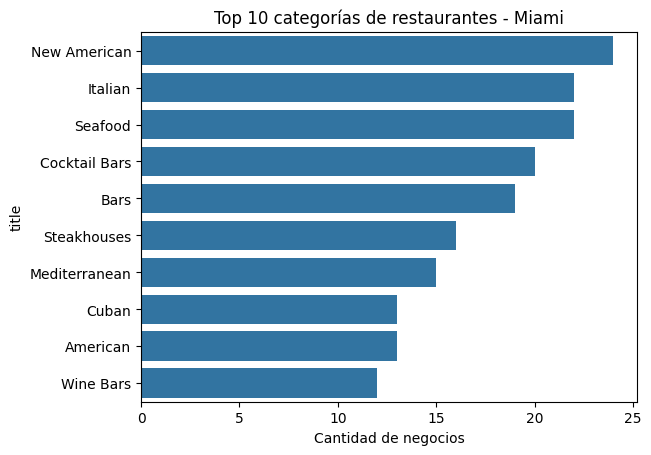

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

top_categorias = df_yelp['title'].value_counts().head(10)
sns.barplot(x=top_categorias.values, y=top_categorias.index)
plt.title('Top 10 categorías de restaurantes - Miami')
plt.xlabel('Cantidad de negocios')
plt.show()

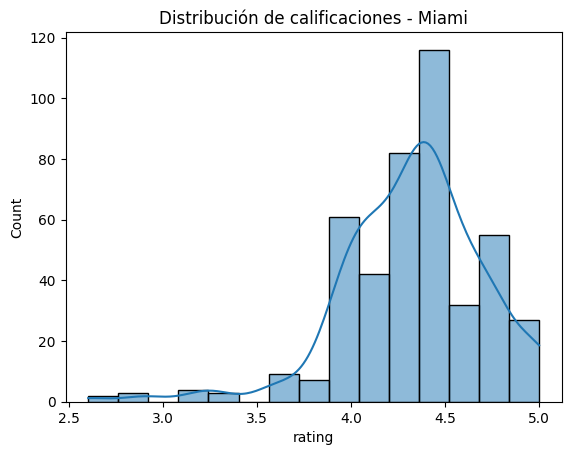

In [28]:
sns.histplot(df_yelp['rating'], bins=15, kde=True)
plt.title('Distribución de calificaciones - Miami')
plt.show()

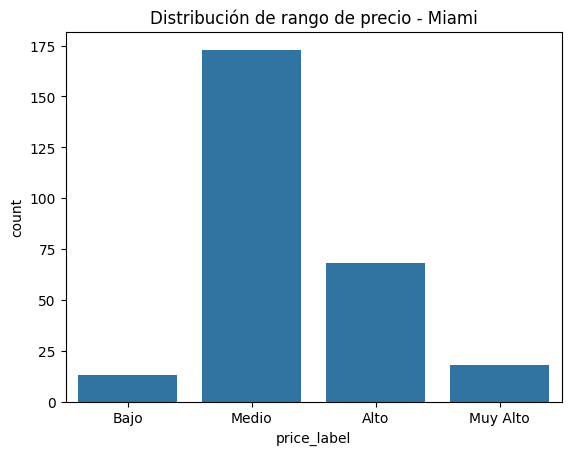

In [30]:
mapa_precio = {'$': 'Bajo', '$$': 'Medio', '$$$': 'Alto', '$$$$': 'Muy Alto'}
df_yelp['price_label'] = df_yelp['price'].map(mapa_precio)

sns.countplot(data=df_yelp, x='price_label', order=['Bajo','Medio','Alto','Muy Alto'])
plt.title('Distribución de rango de precio - Miami')
plt.show()

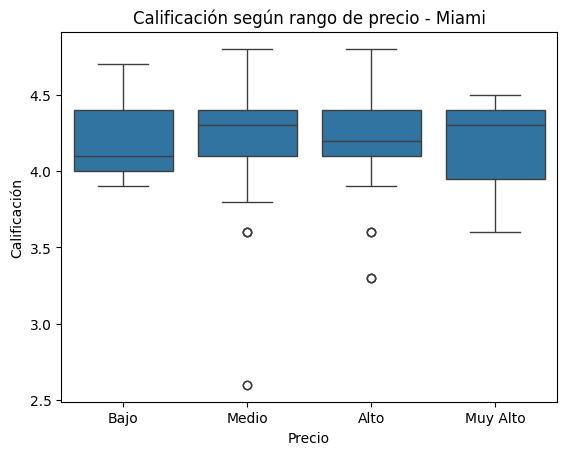

In [32]:
sns.boxplot(data=df_yelp, x='price_label', y='rating', order=['Bajo','Medio','Alto','Muy Alto'])
plt.title('Calificación según rango de precio - Miami')
plt.xlabel('Precio')
plt.ylabel('Calificación')
plt.show()

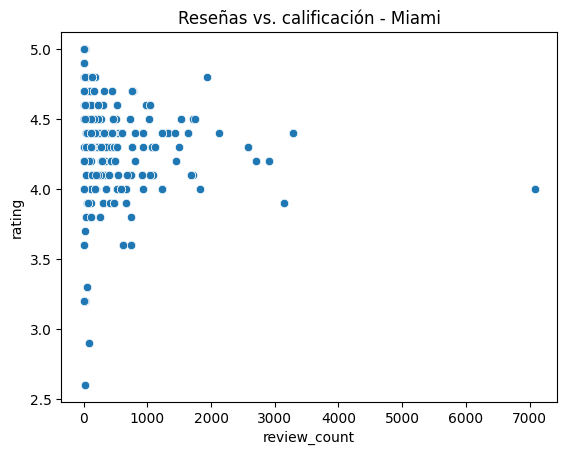

In [31]:
sns.scatterplot(data=df_yelp, x='review_count', y='rating')
plt.title('Reseñas vs. calificación - Miami')
plt.show()

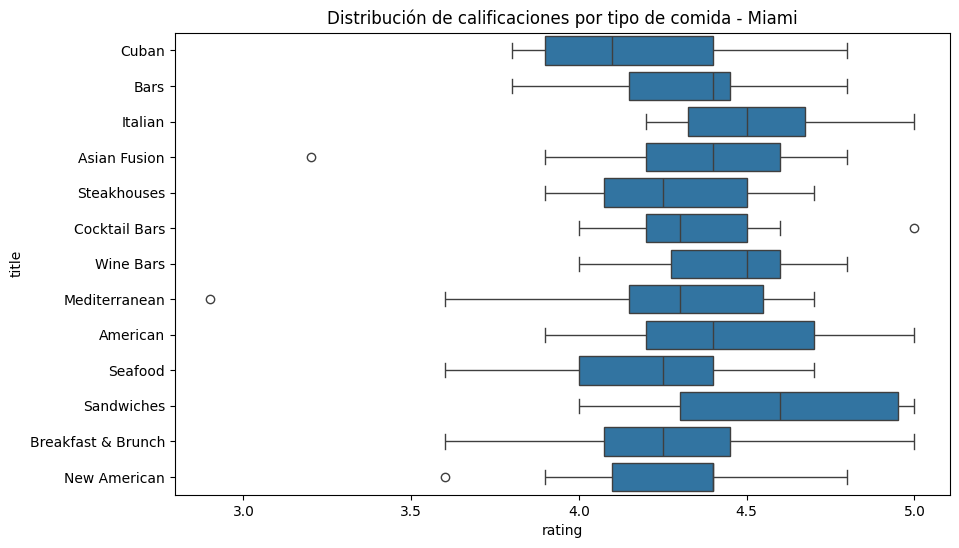

In [34]:
categorias_frecuentes = df_yelp['title'].value_counts()
categorias_frecuentes = categorias_frecuentes[categorias_frecuentes >= 10].index

df_filtrado = df_yelp[df_yelp['title'].isin(categorias_frecuentes)]

plt.figure(figsize=(10,6))
sns.boxplot(data=df_filtrado, x='rating', y='title')
plt.title('Distribución de calificaciones por tipo de comida - Miami')
plt.show()